# Tabular Sarsa($\lambda$): Control for the L-maze grid world

## Installation and Setup

In [85]:
# uncomment if needed
# %pip install gym-classics2

# if the code produces an error, then try to install the package's latest version from github:
# %pip install "gym-classics2 @ git+https://github.com/mhahsler/gym-classics2.git"

In [86]:
import numpy as np
np.set_printoptions(precision=2)

SEED = 42
rng = np.random.default_rng(SEED)

In [87]:
import gymnasium as gym
import gym_classics2

## Define a Grid World With Delayed Rewards

Traces are typically used for problems with **delayed rewards.** To create delayed rewards, I use no step cost and a goal reward of 1.0. 
This means we need to use discounting with $\gamma < 1$ to find short paths.

In [88]:
gym_env = gym.make('LMaze-v0', goal_reward = 1.0, step_reward = 0.0, tabular = True)

env = gym_env.unwrapped
env.reset(seed=SEED)

(30, {})

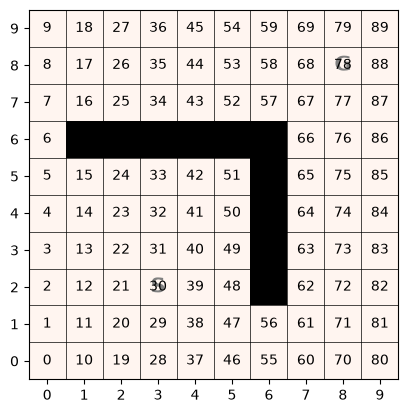

In [89]:
env.image()

In [90]:
from gym_classics2.algorithms.monte_carlo_methods import sample_episode

# helper to visualize the learned policy and value function 
def plot_solution(Q, title=None, path = True, clim = None):
    V = np.max(Q, axis=1)
    pol = np.argmax(Q, axis=1)
    env.image(V, policy=pol, title=title, clim=clim)
    
    if path:
        path = sample_episode(env, policy=pol, max_len=100, rng=rng)
        env.image(V, policy=pol, episode=path, title='Found Path', clim=clim)

## Define Tabular $Sarsa(\lambda)$ 

Add an eligibility trace $E(s,a)$ for each entry of the Q-table. The trace records how recently each state-action pair was visited. The TD error $\delta$ at every step updates all entries in proportion to their trace (replacing traces):

$$\delta = R + \gamma Q(S',A') - Q(S,A), \quad E(S,A) \leftarrow 1, \quad Q \leftarrow Q + \alpha \delta E, \quad E \leftarrow \gamma \lambda E$$

In [91]:
from gym_classics2.algorithms.schedules import Schedule, ConstantSchedule, LinearDecaySchedule
from gym_classics2.utils import random_argmax
from tqdm import tqdm

def tabular_Sarsa_lambda(env, discount, alpha, epsilon, lam, Q=None, n=100, verbose=False,
                 history=False, rng=None):
    """Tabular Sarsa(lambda) with replacing traces. Returns Q (and a history dict if history=True)."""
    rng = np.random.default_rng(rng)
    if not isinstance(alpha, Schedule): alpha = ConstantSchedule(alpha)
    if not isinstance(epsilon, Schedule): epsilon = ConstantSchedule(epsilon)
    if Q is None:
        Q = np.zeros((env.observation_space.n, env.action_space.n))

    def choose(s, eps):
        if rng.random() < eps:
            return rng.integers(env.action_space.n)
        return random_argmax(Q[s, :], rng=rng)

    returns, ep_lens = [], []
    for i in tqdm(range(n), desc="Sarsa(lambda)", disable=verbose):
        s, _ = env.reset()
        a = choose(s, epsilon(i))
        z = np.zeros_like(Q)          # eligibility traces
        done, t, G = False, 0, 0

        while not done:
            sp, r, terminated, truncated, _ = env.step(a)
            done = terminated or truncated
            G += r * discount**t
            t += 1

            ap = choose(sp, epsilon(i))
            target = r if terminated else r + discount * Q[sp, ap]
            delta = target - Q[s, a]

            z[s, a] = 1                           # replacing trace
            Q += alpha(i) * delta * z             # update all traced entries
            z *= discount * lam                   # decay traces

            if verbose:
                print(f"{t}: S={s}, A={a}, R={r}, S'={sp}, A'={ap}, delta={delta:.3f}, "
                      f"entries with z>0: {np.count_nonzero(z)}")
            s, a = sp, ap

        returns.append(G)
        ep_lens.append(t)

    if history:
        return Q, {'returns': returns, 'ep_lens': ep_lens}
    return Q

## Compare Updates after One Episode: Sarsa(0) vs. Sarsa($\lambda$)

In [92]:
from gym_classics2.algorithms.temporal_difference_learning import Sarsa_0

Q = Sarsa_0(env, discount=.95, alpha=ConstantSchedule(0.1), epsilon=ConstantSchedule(0.5),
            n=1, verbose=True, rng=rng)

--- Episode 0 ---
1 - sarsa: 30,2,0.0,29,1, - new Q(s,a): 0.0
2 - sarsa: 29,1,0.0,38,0, - new Q(s,a): 0.0
3 - sarsa: 38,0,0.0,39,0, - new Q(s,a): 0.0
4 - sarsa: 39,0,0.0,40,2, - new Q(s,a): 0.0
5 - sarsa: 40,2,0.0,39,3, - new Q(s,a): 0.0
6 - sarsa: 39,3,0.0,30,2, - new Q(s,a): 0.0
7 - sarsa: 30,2,0.0,29,1, - new Q(s,a): 0.0
8 - sarsa: 29,1,0.0,38,1, - new Q(s,a): 0.0
9 - sarsa: 38,1,0.0,47,3, - new Q(s,a): 0.0
10 - sarsa: 47,3,0.0,38,0, - new Q(s,a): 0.0
11 - sarsa: 38,0,0.0,39,2, - new Q(s,a): 0.0
12 - sarsa: 39,2,0.0,38,1, - new Q(s,a): 0.0
13 - sarsa: 38,1,0.0,47,2, - new Q(s,a): 0.0
14 - sarsa: 47,2,0.0,46,0, - new Q(s,a): 0.0
15 - sarsa: 46,0,0.0,47,3, - new Q(s,a): 0.0
16 - sarsa: 47,3,0.0,38,3, - new Q(s,a): 0.0
17 - sarsa: 38,3,0.0,29,0, - new Q(s,a): 0.0
18 - sarsa: 29,0,0.0,30,2, - new Q(s,a): 0.0
19 - sarsa: 30,2,0.0,29,0, - new Q(s,a): 0.0
20 - sarsa: 29,0,0.0,30,1, - new Q(s,a): 0.0
21 - sarsa: 30,1,0.0,39,3, - new Q(s,a): 0.0
22 - sarsa: 39,3,0.0,30,0, - new Q(s,a): 0.0
2

Sarsa(0) updates a Q-value only when the reward of 1 is received in the last step, so only the last state-action pair changes.

Updated entries: 1


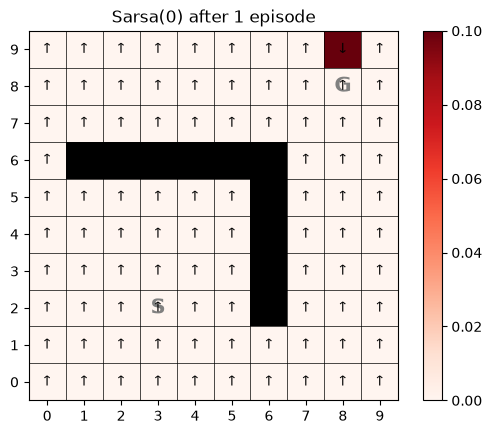

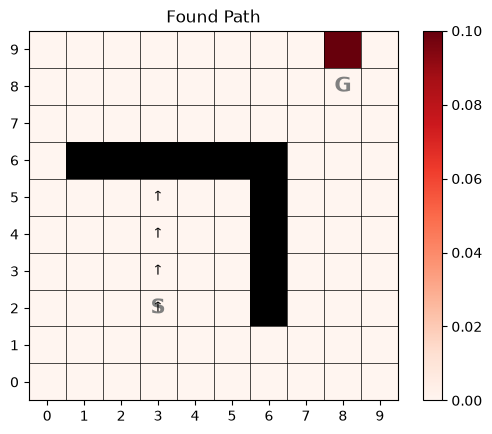

In [93]:
print("Updated entries:", np.count_nonzero(Q))
plot_solution(Q, path = True, title = "Sarsa(0) after 1 episode")

In [94]:
Q = tabular_Sarsa_lambda(env, discount=.95, alpha=ConstantSchedule(0.1), epsilon=ConstantSchedule(0.5),
                 lam=0.9, n=1, verbose=True, rng=rng)

1: S=30, A=1, R=0.0, S'=39, A'=0, delta=0.000, entries with z>0: 1
2: S=39, A=0, R=0.0, S'=40, A'=1, delta=0.000, entries with z>0: 2
3: S=40, A=1, R=0.0, S'=49, A'=0, delta=0.000, entries with z>0: 3
4: S=49, A=0, R=0.0, S'=50, A'=2, delta=0.000, entries with z>0: 4
5: S=50, A=2, R=0.0, S'=49, A'=0, delta=0.000, entries with z>0: 5
6: S=49, A=0, R=0.0, S'=50, A'=3, delta=0.000, entries with z>0: 5
7: S=50, A=3, R=0.0, S'=41, A'=3, delta=0.000, entries with z>0: 6
8: S=41, A=3, R=0.0, S'=32, A'=2, delta=0.000, entries with z>0: 7
9: S=32, A=2, R=0.0, S'=31, A'=3, delta=0.000, entries with z>0: 8
10: S=31, A=3, R=0.0, S'=22, A'=0, delta=0.000, entries with z>0: 9
11: S=22, A=0, R=0.0, S'=23, A'=3, delta=0.000, entries with z>0: 10
12: S=23, A=3, R=0.0, S'=14, A'=1, delta=0.000, entries with z>0: 11
13: S=14, A=1, R=0.0, S'=23, A'=3, delta=0.000, entries with z>0: 12
14: S=23, A=3, R=0.0, S'=14, A'=2, delta=0.000, entries with z>0: 12
15: S=14, A=2, R=0.0, S'=13, A'=2, delta=0.000, entri

The reward is still only received in the last step, but the traces remember all earlier state-action pairs, so they are updated too (more strongly the closer they are to the goal).

Updated entries: 124


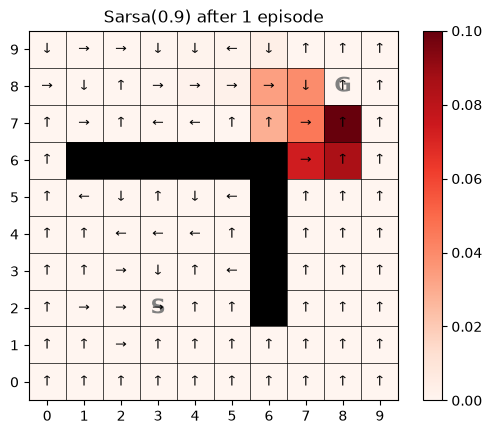

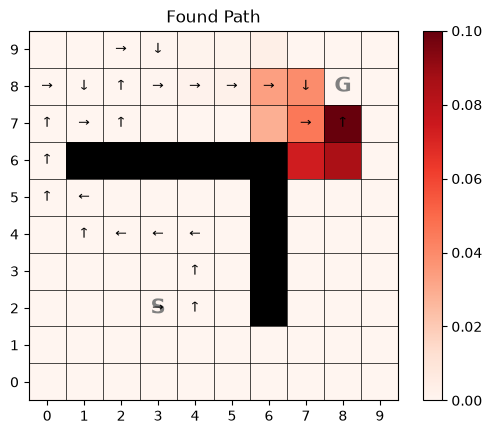

In [95]:
print("Updated entries:", np.count_nonzero(Q))
plot_solution(Q, title = "Sarsa(0.9) after 1 episode")

With a high $\lambda$ (close to Monte Carlo), a single episode updates many more entries.

## Run Sarsa($\lambda$)

This implementation also keeps return histories.

In [96]:
Q, history = tabular_Sarsa_lambda(env, 
                                  discount=.95, 
                                  alpha=LinearDecaySchedule(0.1, 0.001, 500),
                                  epsilon=LinearDecaySchedule(1, 0.0, 500),
                                  lam=0.5, 
                                  n=1000, history=True, rng=rng)

Sarsa(lambda): 100%|██████████| 1000/1000 [00:01<00:00, 838.65it/s]


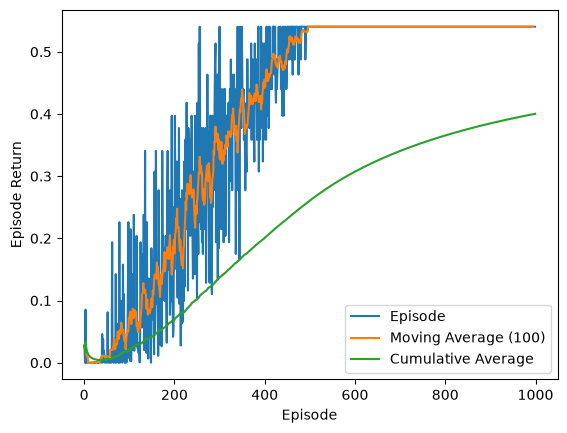

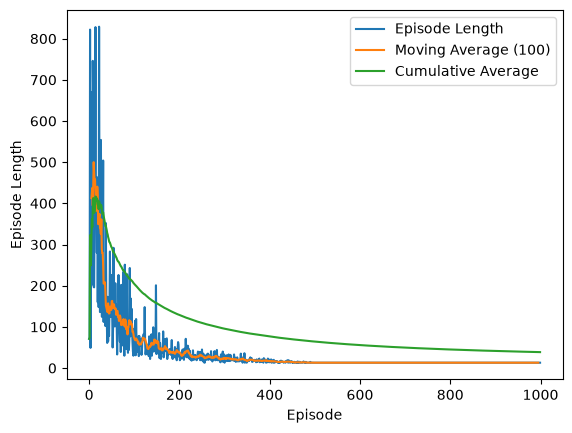

In [97]:
from gym_classics2.performance import plot_returns, plot_episode_lengths
plot_returns(history['returns'], window_size= 10)
plot_episode_lengths(history['ep_lens'], window_size= 10)

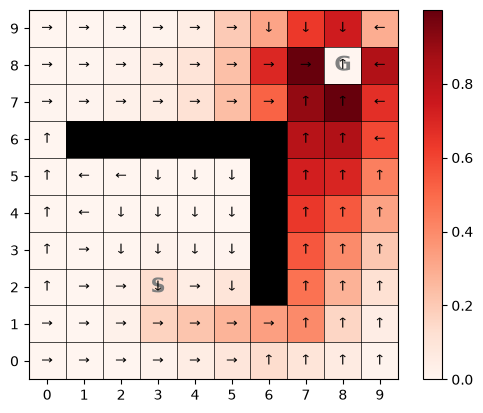

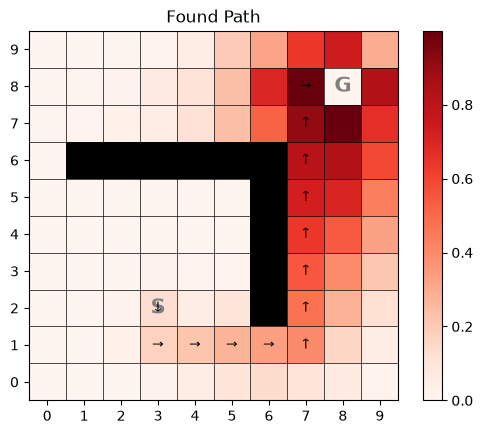

In [98]:
plot_solution(Q)

## Effect of $\lambda$

Compare the average return for different values of $\lambda$ (mean of 5 runs; $\lambda=0$ is Sarsa(0)).

Sarsa(lambda): 100%|██████████| 200/200 [00:00<00:00, 593.82it/s]


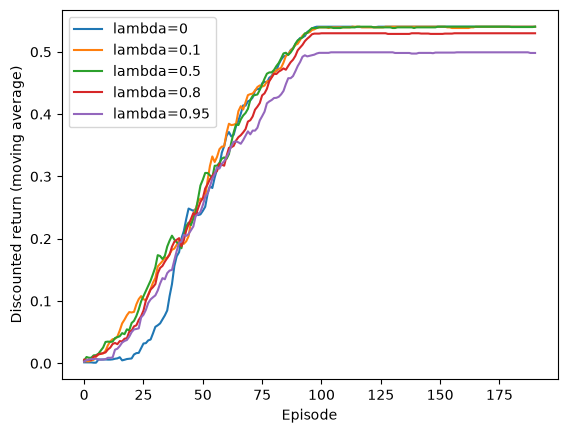

In [99]:
import matplotlib.pyplot as plt

for lam in [0, 0.1, 0.5, 0.8, 0.95]:
    runs = [tabular_Sarsa_lambda(env, discount=.95, 
                                 alpha=LinearDecaySchedule(0.1, 0.001, 100),
                                 epsilon=LinearDecaySchedule(1, 0.001, 100), 
                                 lam=lam, n=200,
                                 history=True, rng=rng)[1]['returns'] for _ in range(5)]
    plt.plot(np.convolve(np.mean(runs, axis=0), np.ones(10)/10, mode='valid'), label=f'lambda={lam}')
plt.xlabel('Episode'); plt.ylabel('Discounted return (moving average)'); plt.legend(); plt.show()


&copy; 2025 [Michael Hahsler](https://michael.hahsler.net). 
This work is openly licensed under [Creative Commons Attribution-ShareAlike 4.0 International (CC BY-SA 4.0) License](https://creativecommons.org/licenses/by-sa/4.0/)

![CC BY-SA 4.0](https://licensebuttons.net/l/by-sa/3.0/88x31.png)